In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print(cv2.__version__)

4.14.0


Saving building.jpg to building (1).jpg


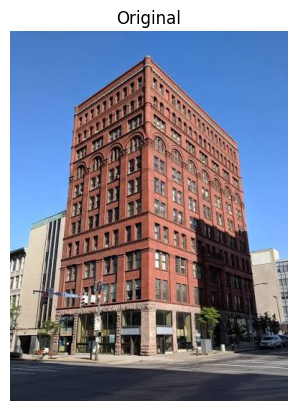

In [2]:
uploaded = files.upload()          # choose any clear image (building, object, book, etc.)
img_path = list(uploaded.keys())[0]

img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV reads BGR, matplotlib needs RGB
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(img_rgb); plt.title("Original"); plt.axis("off"); plt.show()

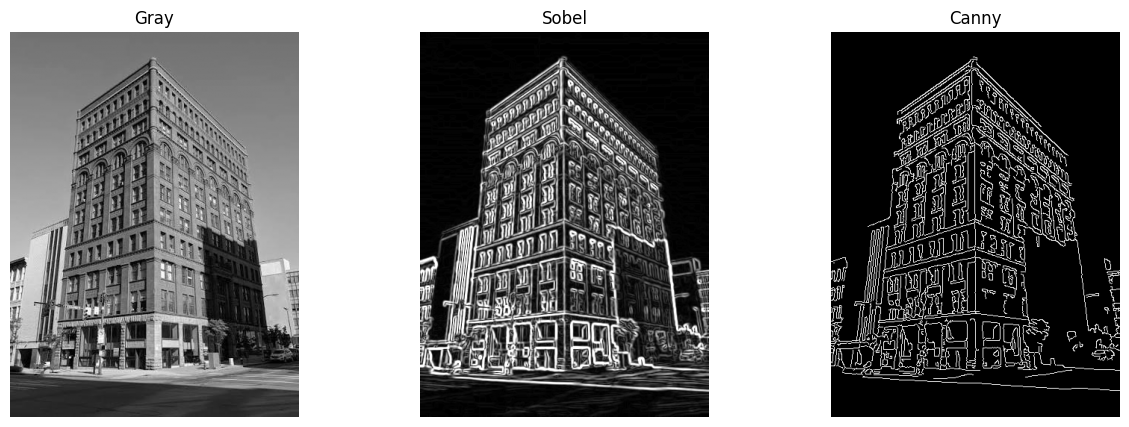

True

In [3]:
blur = cv2.GaussianBlur(gray, (5,5), 0)          # remove noise first
sobelx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobelx, sobely))
canny = cv2.Canny(blur, 100, 200)

fig, ax = plt.subplots(1, 3, figsize=(15,5))
for a, im, t in zip(ax, [gray, sobel, canny], ["Gray", "Sobel", "Canny"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.show()

cv2.imwrite("edges_canny.png", canny)   # required output file
cv2.imwrite("edges_sobel.png", sobel)

SIFT keypoints: 1932
SIFT descriptor shape: (1932, 128)


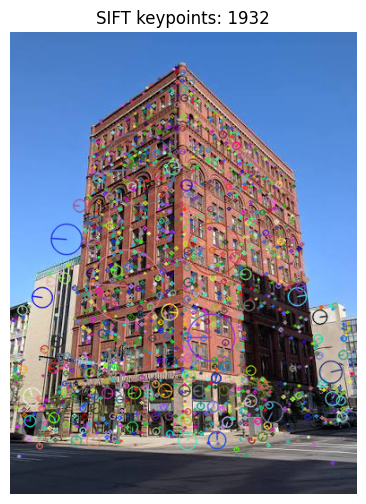

True

In [4]:
sift = cv2.SIFT_create()
kp_sift, des_sift = sift.detectAndCompute(gray, None)

print("SIFT keypoints:", len(kp_sift))
print("SIFT descriptor shape:", des_sift.shape)   # (keypoints, 128)

img_sift = cv2.drawKeypoints(
    img, kp_sift, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(8,6))
plt.imshow(cv2.cvtColor(img_sift, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT keypoints: {len(kp_sift)}"); plt.axis("off"); plt.show()

cv2.imwrite("keypoints_sift.png", img_sift)

ORB keypoints: 1000
ORB descriptor shape: (1000, 32)


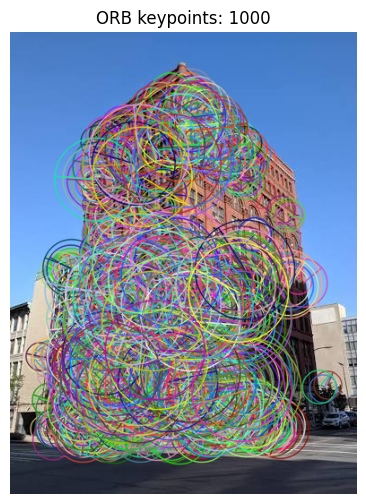

True

In [5]:
orb = cv2.ORB_create(nfeatures=1000)
kp_orb, des_orb = orb.detectAndCompute(gray, None)

print("ORB keypoints:", len(kp_orb))
print("ORB descriptor shape:", des_orb.shape)    # (keypoints, 32)

img_orb = cv2.drawKeypoints(
    img, kp_orb, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(8,6))
plt.imshow(cv2.cvtColor(img_orb, cv2.COLOR_BGR2RGB))
plt.title(f"ORB keypoints: {len(kp_orb)}"); plt.axis("off"); plt.show()

cv2.imwrite("keypoints_orb.png", img_orb)

In [6]:
print(f"{'Method':<6} {'Keypoints':<10} {'Descriptor size':<16} {'dtype'}")
print(f"{'SIFT':<6} {len(kp_sift):<10} {des_sift.shape[1]:<16} {des_sift.dtype}")
print(f"{'ORB':<6} {len(kp_orb):<10} {des_orb.shape[1]:<16} {des_orb.dtype}")

Method Keypoints  Descriptor size  dtype
SIFT   1932       128              float32
ORB    1000       32               uint8


Image 1 upload karo


Saving shop.jpg to shop.jpg
Image 2 upload karo


Saving shop1.jpg to shop1.jpg


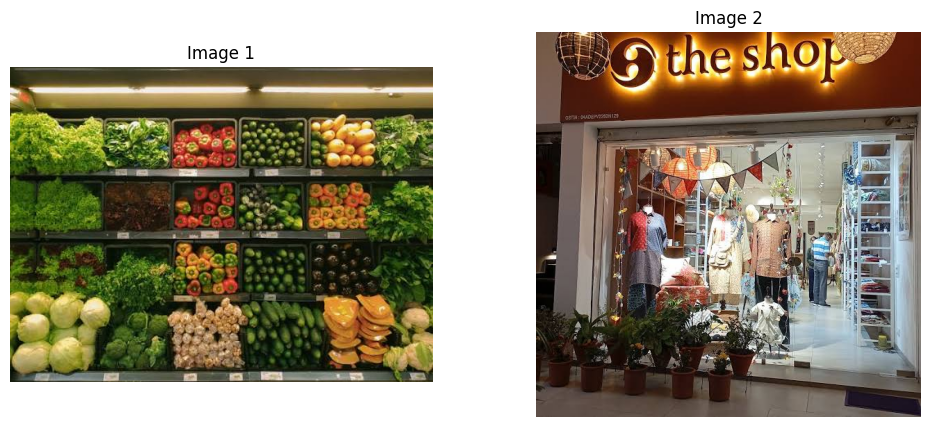

In [7]:
print("Image 1 upload karo")
up1 = files.upload()
path1 = list(up1.keys())[0]

print("Image 2 upload karo")
up2 = files.upload()
path2 = list(up2.keys())[0]

img1 = cv2.imread(path1)
img2 = cv2.imread(path2)
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)); ax[0].set_title("Image 1"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)); ax[1].set_title("Image 2"); ax[1].axis("off")
plt.show()

In [8]:
def resize_max(im, max_side=1000):
    h, w = im.shape[:2]
    s = max_side / max(h, w)
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

img1, img2 = resize_max(img1), resize_max(img2)
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

Keypoints: 3021 1803
Total matches: 3021 | Good matches: 15


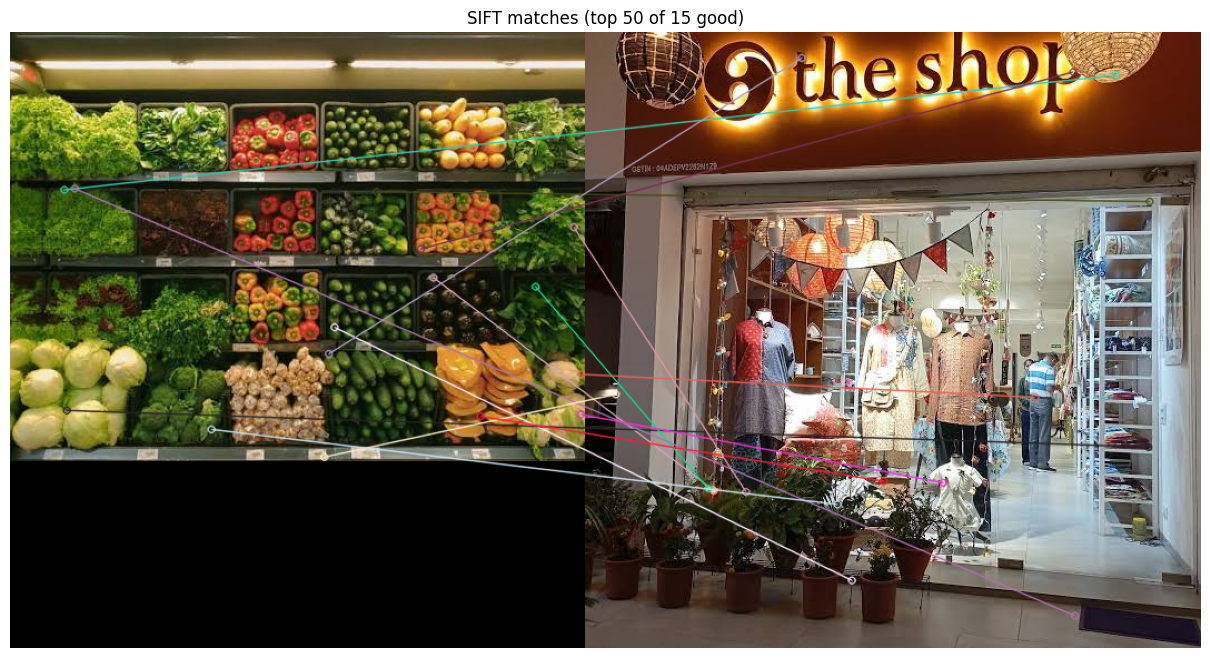

True

In [9]:
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)
print("Keypoints:", len(kp1), len(kp2))

bf = cv2.BFMatcher(cv2.NORM_L2)
knn = bf.knnMatch(des1, des2, k=2)       # har point ke 2 best candidates

good = []
for m, n in knn:
    if m.distance < 0.75 * n.distance:   # ratio test
        good.append(m)
print("Total matches:", len(knn), "| Good matches:", len(good))

good = sorted(good, key=lambda x: x.distance)
vis = cv2.drawMatches(img1, kp1, img2, kp2, good[:50], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(16,8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"SIFT matches (top 50 of {len(good)} good)"); plt.axis("off"); plt.show()

cv2.imwrite("matches_sift.png", vis)

ORB good matches: 6


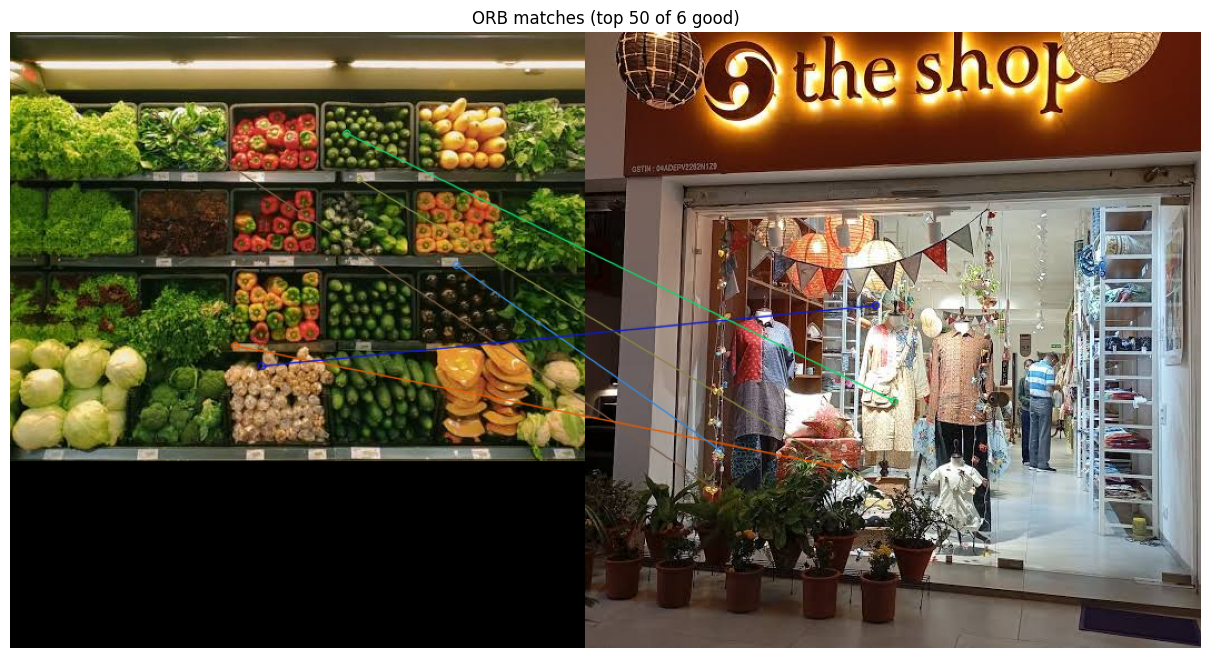

True

In [10]:
orb = cv2.ORB_create(nfeatures=1500)
kp1o, des1o = orb.detectAndCompute(gray1, None)
kp2o, des2o = orb.detectAndCompute(gray2, None)

bf_orb = cv2.BFMatcher(cv2.NORM_HAMMING)   # binary descriptor = Hamming distance
knn_o = bf_orb.knnMatch(des1o, des2o, k=2)

good_o = []
for pair in knn_o:
    if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance:
        good_o.append(pair[0])
print("ORB good matches:", len(good_o))

good_o = sorted(good_o, key=lambda x: x.distance)
vis_o = cv2.drawMatches(img1, kp1o, img2, kp2o, good_o[:50], None,
                        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
plt.figure(figsize=(16,8))
plt.imshow(cv2.cvtColor(vis_o, cv2.COLOR_BGR2RGB))
plt.title(f"ORB matches (top 50 of {len(good_o)} good)"); plt.axis("off"); plt.show()

cv2.imwrite("matches_orb.png", vis_o)

Inliers after RANSAC: 5 of 15


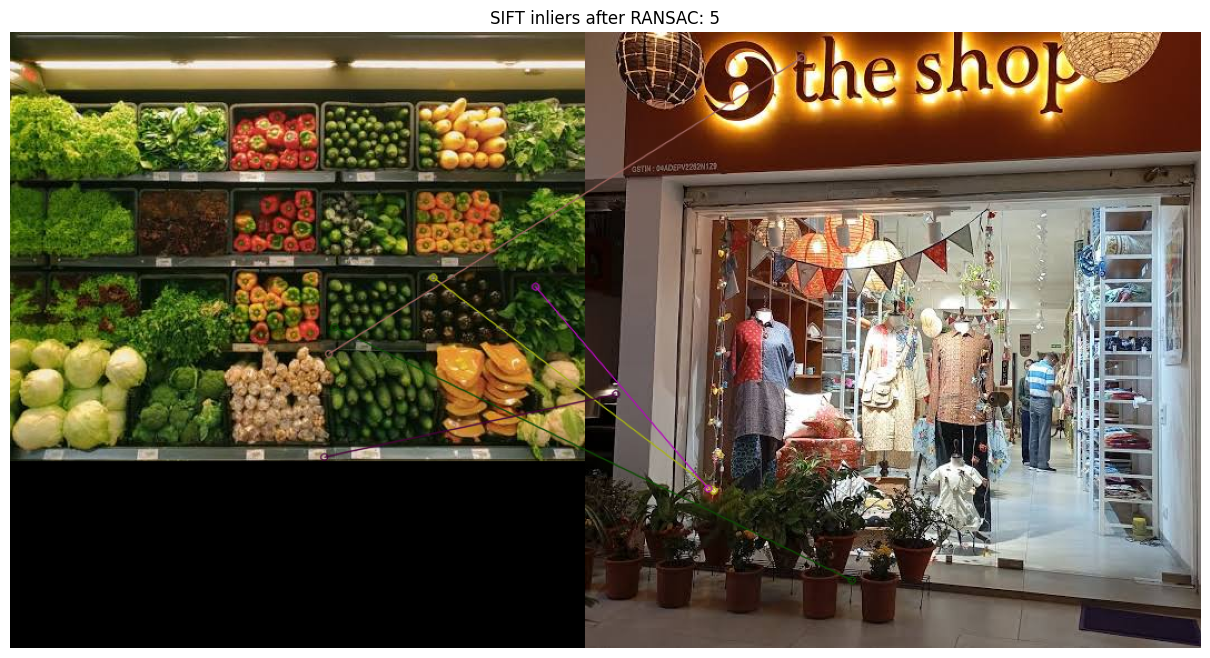

In [11]:
if len(good) >= 4:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    inliers = [m for m, ok in zip(good, mask.ravel()) if ok]
    print("Inliers after RANSAC:", len(inliers), "of", len(good))

    vis_in = cv2.drawMatches(img1, kp1, img2, kp2, inliers[:50], None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    plt.figure(figsize=(16,8))
    plt.imshow(cv2.cvtColor(vis_in, cv2.COLOR_BGR2RGB))
    plt.title(f"SIFT inliers after RANSAC: {len(inliers)}"); plt.axis("off"); plt.show()
    cv2.imwrite("matches_sift_ransac.png", vis_in)

In [12]:
print(f"{'Method':<6} {'KP img1':<9} {'KP img2':<9} {'Good matches'}")
print(f"{'SIFT':<6} {len(kp1):<9} {len(kp2):<9} {len(good)}")
print(f"{'ORB':<6} {len(kp1o):<9} {len(kp2o):<9} {len(good_o)}")

Method KP img1   KP img2   Good matches
SIFT   3021      1803      15
ORB    1500      1500      6


In [14]:
from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

data = fetch_olivetti_faces()
imgs, labels = data.images, data.target          # imgs: (400, 64, 64), values 0-1

class_ids = [0, 1, 2, 3, 4]                      # 5 log
names = [f"person_{c}" for c in class_ids]

X_all, y_all = [], []
for new_label, c in enumerate(class_ids):
    for im in imgs[labels == c]:
        im8 = (im * 255).astype(np.uint8)                 # float -> uint8
        im8 = cv2.resize(im8, (128, 128))                 # SIFT ke liye bara karo
        X_all.append(cv2.cvtColor(im8, cv2.COLOR_GRAY2RGB))  # taake purana code chale
        y_all.append(new_label)

X_all, y_all = np.array(X_all), np.array(y_all)
print(X_all.shape, names)                        # (50, 128, 128, 3)

X_tr, X_te, y_tr, y_te = train_test_split(
    X_all, y_all, test_size=0.3, stratify=y_all, random_state=42)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(50, 128, 128, 3) ['person_0', 'person_1', 'person_2', 'person_3', 'person_4']


In [15]:
sift = cv2.SIFT_create()

def get_desc(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    g = cv2.resize(g, (128, 128))
    kps = [cv2.KeyPoint(float(x), float(y), 16)
           for y in range(8, 128, 16) for x in range(8, 128, 16)]   # 8x8 = 64 points
    _, des = sift.compute(g, kps)
    return des                                  # shape (64, 128)

des_tr = [get_desc(im) for im in X_tr]
des_te = [get_desc(im) for im in X_te]
print("Train images:", len(des_tr), "| Test images:", len(des_te))
print("Per image descriptors:", des_tr[0].shape)

Train images: 35 | Test images: 15
Per image descriptors: (64, 128)


In [16]:
from sklearn.cluster import KMeans

K = 30
all_des = np.vstack(des_tr)                     # sirf train se vocabulary
kmeans = KMeans(n_clusters=K, random_state=42, n_init=5).fit(all_des)

def to_hist(des):
    words = kmeans.predict(des)
    h = np.bincount(words, minlength=K).astype(float)
    return h / h.sum()

Xf_tr = np.array([to_hist(d) for d in des_tr])
Xf_te = np.array([to_hist(d) for d in des_te])
print("Feature vector shape:", Xf_tr.shape)     # (35, 30)

Feature vector shape: (35, 30)


In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

scaler = StandardScaler().fit(Xf_tr)
Xs_tr, Xs_te = scaler.transform(Xf_tr), scaler.transform(Xf_te)

svm = SVC(kernel="rbf", C=10, gamma="scale").fit(Xs_tr, y_tr)
knn = KNeighborsClassifier(n_neighbors=3).fit(Xs_tr, y_tr)

pred_svm = svm.predict(Xs_te)
pred_knn = knn.predict(Xs_te)
print("Training complete")

Training complete



===== SVM =====
Accuracy: 0.6667
              precision    recall  f1-score   support

    person_0      1.000     0.667     0.800         3
    person_1      1.000     0.667     0.800         3
    person_2      0.400     0.667     0.500         3
    person_3      0.500     0.333     0.400         3
    person_4      0.750     1.000     0.857         3

    accuracy                          0.667        15
   macro avg      0.730     0.667     0.671        15
weighted avg      0.730     0.667     0.671        15


===== k-NN =====
Accuracy: 0.6
              precision    recall  f1-score   support

    person_0      1.000     0.333     0.500         3
    person_1      0.667     0.667     0.667         3
    person_2      0.500     0.333     0.400         3
    person_3      0.400     0.667     0.500         3
    person_4      0.750     1.000     0.857         3

    accuracy                          0.600        15
   macro avg      0.663     0.600     0.585        15
weighted av

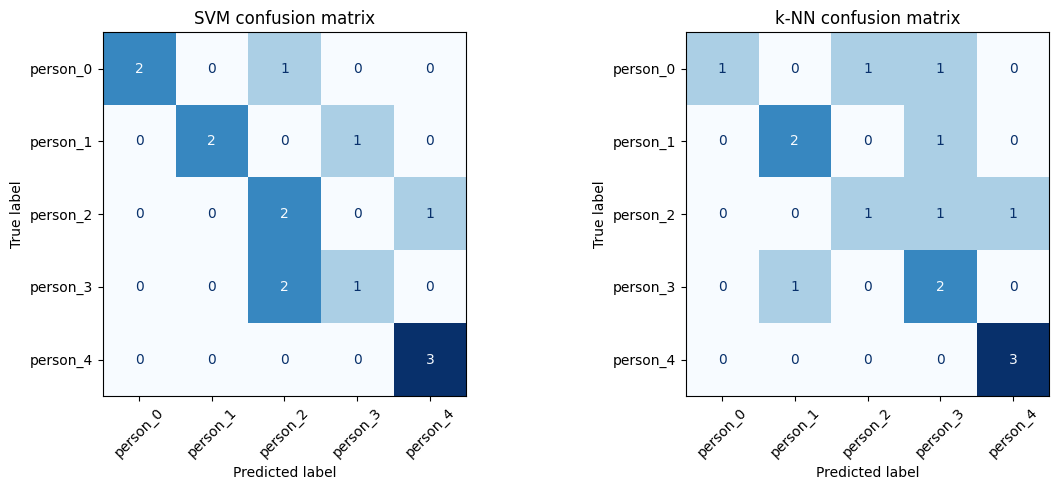

Saved: confusion_matrices.png, metrics.txt


In [18]:
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

results = [("SVM", pred_svm), ("k-NN", pred_knn)]

for name, pred in results:
    print(f"\n===== {name} =====")
    print("Accuracy:", round(accuracy_score(y_te, pred), 4))
    print(classification_report(y_te, pred, target_names=names, digits=3, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (name, pred) in zip(ax, results):
    cm = confusion_matrix(y_te, pred)
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{name} confusion matrix")
    a.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

with open("metrics.txt", "w") as f:
    for name, pred in results:
        f.write(f"===== {name} =====\n")
        f.write(f"Accuracy: {accuracy_score(y_te, pred):.4f}\n")
        f.write(classification_report(y_te, pred, target_names=names, digits=3, zero_division=0) + "\n")
print("Saved: confusion_matrices.png, metrics.txt")

In [19]:
import os
needed = ["edges_canny.png", "edges_sobel.png", "keypoints_sift.png", "keypoints_orb.png",
          "matches_sift.png", "matches_orb.png", "matches_sift_ransac.png",
          "confusion_matrices.png", "metrics.txt"]
for f in needed:
    print("OK     " if os.path.exists(f) else "MISSING", f)

OK      edges_canny.png
OK      edges_sobel.png
OK      keypoints_sift.png
OK      keypoints_orb.png
OK      matches_sift.png
OK      matches_orb.png
OK      matches_sift_ransac.png
OK      confusion_matrices.png
OK      metrics.txt


In [20]:
!pip -q install reportlab
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Image, Table, TableStyle, PageBreak
from reportlab.lib import colors
from sklearn.metrics import precision_recall_fscore_support
from PIL import Image as PILImage

# ====== TUM YE TEXT APNE RESULTS DEKH KAR EDIT KARO ======
TEXT = {
 "intro": "This report covers edge detection, keypoint detection with SIFT and ORB, descriptor matching between two related images, and classification of extracted features using SVM and k-NN. All work was done in Google Colab using OpenCV and scikit-learn.",
 "edges": "Sobel and Canny edge detectors were applied after Gaussian blur. Sobel gives thicker edges and shows the strength of intensity change. Canny gives thin, clean edges because of non-maximum suppression and hysteresis thresholds (100 and 200). Canny looked better in my image because ...",
 "keypoints": "SIFT and ORB were used to detect keypoints and compute descriptors. SIFT descriptors have 128 float values and are very robust to scale and rotation. ORB descriptors are 32-byte binary vectors and are much faster. Keypoints appeared mostly on corners and textured regions.",
 "matching": "Descriptors of two related images were matched with BFMatcher and Lowe's ratio test (0.75). SIFT used L2 distance and ORB used Hamming distance. RANSAC was used to remove wrong matches. Most matched lines connected the same physical points, while wrong matches appeared in ...",
 "classification": "Dense SIFT descriptors were extracted on a regular grid, clustered with K-Means (K=30) to build a visual vocabulary, and each image was converted into a histogram of visual words. SVM (RBF kernel) and k-NN (k=3) were trained on these histograms using the Olivetti Faces dataset (5 people, 70/30 split).",
 "conclusion": "SVM / k-NN performed better because ... The test set is small, so results can change with one wrong prediction. Using more images or more classes would give more reliable results.",
}
# =========================================================

ss = getSampleStyleSheet()
H1, H2, P = ss["Heading1"], ss["Heading2"], ss["BodyText"]

def img(path, w):
    iw, ih = PILImage.open(path).size
    return Image(path, width=w*cm, height=w*cm*ih/iw)

def safe(name):
    return globals().get(name)

story = [Paragraph("Feature Detection, Descriptors and Traditional Classification", H1),
         Paragraph("Weeks 4-7 | CLO2/CLO3", P), Spacer(1, 8),
         Paragraph("1. Introduction", H2), Paragraph(TEXT["intro"], P),
         Paragraph("2. Edge Detection", H2), Paragraph(TEXT["edges"], P),
         Table([[img("edges_sobel.png", 8), img("edges_canny.png", 8)]]),
         Paragraph("Left: Sobel, Right: Canny", P), PageBreak()]

# Keypoints
n_sift = len(kp_sift); n_orb = len(kp_orb)
t = Table([["Method", "Keypoints", "Descriptor size"],
           ["SIFT", n_sift, des_sift.shape[1]], ["ORB", n_orb, des_orb.shape[1]]])
t.setStyle(TableStyle([("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                       ("BACKGROUND", (0,0), (-1,0), colors.lightgrey)]))
story += [Paragraph("3. Keypoints and Descriptors", H2), Paragraph(TEXT["keypoints"], P), t, Spacer(1, 6),
          Table([[img("keypoints_sift.png", 8), img("keypoints_orb.png", 8)]]),
          Paragraph("Left: SIFT, Right: ORB", P), PageBreak()]

# Matching
inl = safe("inliers")
inl_txt = f" After RANSAC, {len(inl)} inliers remained." if inl is not None else ""
story += [Paragraph("4. Descriptor Matching", H2), Paragraph(TEXT["matching"], P),
          Paragraph(f"SIFT good matches: {len(good)}. ORB good matches: {len(good_o)}.{inl_txt}", P),
          img("matches_sift.png", 16), Spacer(1, 4), img("matches_orb.png", 16), PageBreak()]

# Classification + metrics
rows = [["Model", "Accuracy", "Precision", "Recall", "F1-score"]]
for name, pred in [("SVM", pred_svm), ("k-NN", pred_knn)]:
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, average="macro", zero_division=0)
    rows.append([name, f"{accuracy_score(y_te, pred):.3f}", f"{p:.3f}", f"{r:.3f}", f"{f:.3f}"])
t2 = Table(rows)
t2.setStyle(TableStyle([("GRID", (0,0), (-1,-1), 0.5, colors.grey),
                        ("BACKGROUND", (0,0), (-1,0), colors.lightgrey)]))
story += [Paragraph("5. Classification and Metrics", H2), Paragraph(TEXT["classification"], P), t2,
          Paragraph("Precision, recall and F1 are macro averages over all classes.", P), Spacer(1, 6),
          img("confusion_matrices.png", 16),
          Paragraph("6. Conclusion", H2), Paragraph(TEXT["conclusion"], P)]

SimpleDocTemplate("Assignment_Report.pdf", pagesize=A4,
                  leftMargin=2*cm, rightMargin=2*cm, topMargin=2*cm, bottomMargin=2*cm).build(story)
print("Report saved: Assignment_Report.pdf")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.8 MB/s eta 0:00:00
Report saved: Assignment_Report.pdf


In [21]:
!zip -q outputs.zip *.png metrics.txt Assignment_Report.pdf
files.download("Assignment_Report.pdf")
files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>